# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** ______________________ &nbsp;&nbsp; **Roll No.:** ____________ &nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

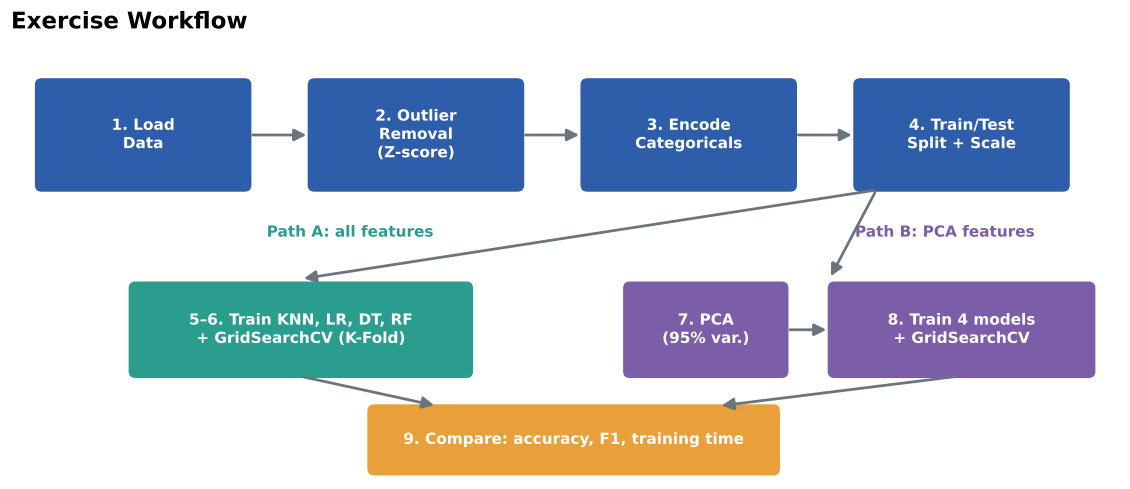

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
import os
path = "Exercise/heart.csv" if os.path.exists("Exercise/heart.csv") else "heart.csv"
df = pd.read_csv(path)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print("Dimensions (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)
df.info()

Dimensions (rows, columns): (918, 12)

Column names: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 

### 1.3 Check for missing values

In [4]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nHidden missing values (zeros that are medically impossible):")
print("Cholesterol == 0 :", (df["Cholesterol"] == 0).sum())
print("RestingBP   == 0 :", (df["RestingBP"] == 0).sum())
df.describe()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing values: 0

Hidden missing values (zeros that are medically impossible):
Cholesterol == 0 : 172
RestingBP   == 0 : 1


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
1    508
0    410
Name: count, dtype: int64

Percentage:
HeartDisease
1    55.34
0    44.66
Name: proportion, dtype: float64


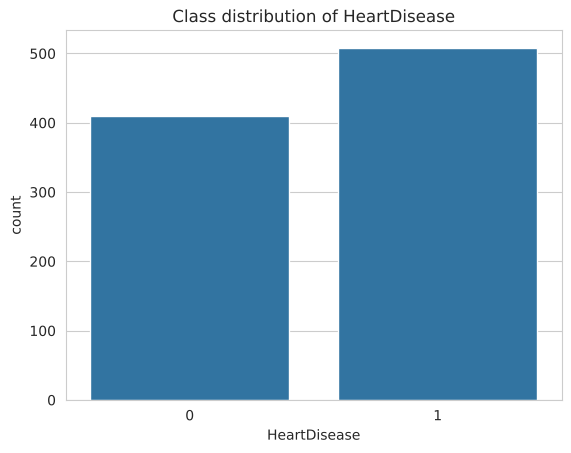

In [5]:
counts = df["HeartDisease"].value_counts()
print(counts)
print("\nPercentage:")
print((df["HeartDisease"].value_counts(normalize=True) * 100).round(2))
sns.countplot(x="HeartDisease", data=df)
plt.title("Class distribution of HeartDisease")
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> The dataset has **918 rows and 12 columns** (11 features + the target `HeartDisease`). Five columns are text-based: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina` and `ST_Slope`. There are **no missing values (NaN)** in any column.
>
> However, there are **hidden missing values**: `Cholesterol` has **172 records equal to 0** and `RestingBP` has **1 record equal to 0**, both medically impossible. (`Oldpeak` also has negative values, min = -2.6, which are valid ST depressions/elevations.) The assignment pipeline does not ask for imputation, so these zeros were kept; I flag them as a limitation. The classes are fairly balanced: 508 with heart disease (55.3%) vs 410 without (44.7%).

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

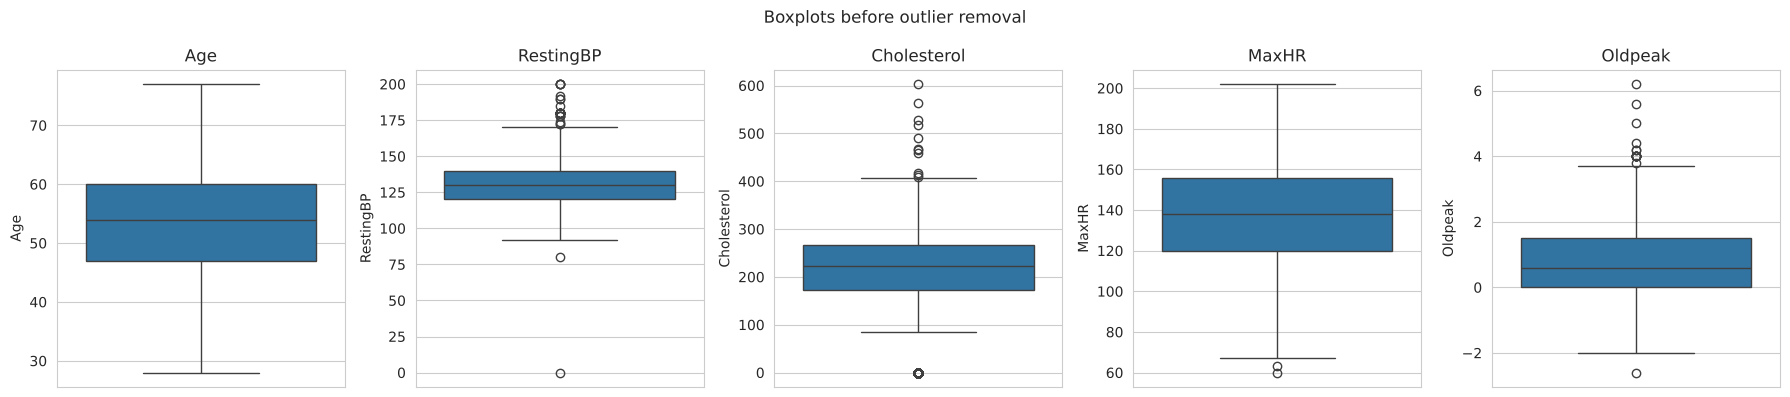

In [6]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots before outlier removal")
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
z_scores = pd.DataFrame(stats.zscore(df[num_cols]), columns=num_cols, index=df.index)
z_scores.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [8]:
outlier_mask = (z_scores.abs() > 3)          # True where |z| > 3
outlier_rows = outlier_mask.any(axis=1)      # a record is an outlier if ANY feature is
print("Outliers per feature:")
print(outlier_mask.sum())
print("\nTotal outlier records:", outlier_rows.sum())

Outliers per feature:
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64

Total outlier records: 19


### 2.4 Remove the outliers and display the new shape

In [9]:
print("Shape before removal:", df.shape)
df_clean = df[~outlier_rows].reset_index(drop=True)
print("Shape after removal :", df_clean.shape)
print("Records removed     :", df.shape[0] - df_clean.shape[0])

Shape before removal: (918, 12)
Shape after removal : (899, 12)
Records removed     : 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> **19 records were removed** (918 → 899 rows). Outlier records per feature (|z| > 3): `RestingBP` = 8, `Oldpeak` = 7, `Cholesterol` = 3, `MaxHR` = 1, `Age` = 0. So **`RestingBP` contributed the most outliers**. The counts add up to 19, so no record was an outlier in more than one feature. Note that the 172 zero-valued `Cholesterol` entries inflate the mean/std of that column, so they are *not* flagged by the Z-score method.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
print("Categorical features:", cat_cols)
for col in cat_cols:
    print(f"{col:15s} -> {df_clean[col].unique()}")

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Sex             -> <StringArray>
['M', 'F']
Length: 2, dtype: str
ChestPainType   -> <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
RestingECG      -> <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
ExerciseAngina  -> <StringArray>
['N', 'Y']
Length: 2, dtype: str
ST_Slope        -> <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [11]:
df_enc = df_clean.copy()
binary_cols = ["Sex", "ExerciseAngina"]
le = LabelEncoder()
for col in binary_cols:
    df_enc[col] = le.fit_transform(df_enc[col])
    print(col, "->", dict(zip(le.classes_, le.transform(le.classes_))))
df_enc[binary_cols].head()

Sex -> {'F': np.int64(0), 'M': np.int64(1)}
ExerciseAngina -> {'N': np.int64(0), 'Y': np.int64(1)}


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [12]:
nominal_cols = ["ChestPainType", "RestingECG", "ST_Slope"]
df_enc = pd.get_dummies(df_enc, columns=nominal_cols, drop_first=True, dtype=int)
df_enc.columns.tolist()

['Age',
 'Sex',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'MaxHR',
 'ExerciseAngina',
 'Oldpeak',
 'HeartDisease',
 'ChestPainType_ATA',
 'ChestPainType_NAP',
 'ChestPainType_TA',
 'RestingECG_Normal',
 'RestingECG_ST',
 'ST_Slope_Flat',
 'ST_Slope_Up']

### 3.4 Display the final encoded dataset

In [13]:
print("Shape after encoding:", df_enc.shape)
df_enc.head()

Shape after encoding: (899, 16)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> - `Sex` and `ExerciseAngina` are **binary** (2 categories), so **Label Encoding** (0/1) is sufficient and adds no extra columns.
> - `ChestPainType` (4 categories), `RestingECG` (3) and `ST_Slope` (3) are **nominal with no natural order**, so **One-Hot Encoding** is used. Label encoding would impose a false order (e.g. ASY > NAP > ATA). `drop_first=True` removes one dummy per feature to avoid the dummy-variable trap (perfect multicollinearity).
> - `FastingBS` is already binary/numeric and was left as is.
>
> After encoding the dataset has **16 columns = 15 features + 1 target** (9 original/label-encoded features minus target + 3 + 2 + 2 dummies).

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
X = df_enc.drop("HeartDisease", axis=1)
y = df_enc["HeartDisease"]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (899, 15) | y shape: (899,)


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class ratio :", y_test.value_counts(normalize=True).round(3).to_dict())

X_train: (719, 15) | X_test: (180, 15)
Train class ratio: {1: 0.547, 0: 0.453}
Test class ratio : {1: 0.55, 0: 0.45}


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit ONLY on training data
X_test_scaled = scaler.transform(X_test)         # reuse training mu / sigma
print("Train mean (approx 0):", X_train_scaled.mean().round(3))
print("Train std  (approx 1):", X_train_scaled.std().round(3))

Train mean (approx 0): 0.0
Train std  (approx 1): 1.0


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> I used **StandardScaler** (z-score standardisation): it centres every feature at mean 0 with std 1, which suits KNN (distance-based) and Logistic Regression (gradient/regularisation-based), and it is less distorted by remaining extreme values than Min-Max scaling.
>
> If the scaler were fitted on the **entire dataset before splitting**, the mean and standard deviation would include information from the test records. This is **data leakage**: the test set would no longer be truly unseen, and the reported test performance would be optimistically biased. Fitting on the training set only and re-using its parameters on the test set mimics real deployment.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name="Model", show_cm=True):
    """Train a model, measure training time, return metrics (dict)."""
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    y_pred = model.predict(X_test)
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Train Time (s)": train_time,
    }
    if show_cm:
        cm = confusion_matrix(y_test, y_pred)
        ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(cmap="Blues")
        plt.title(f"Confusion matrix - {name}")
        plt.show()
    return results

results_before = []

### 5.2 K-Nearest Neighbors

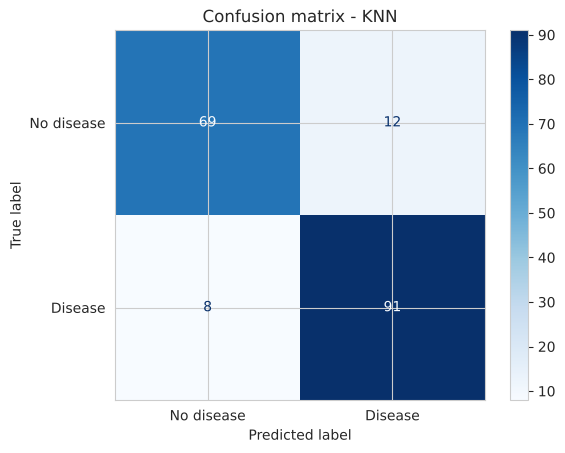

{'Model': 'KNN',
 'Accuracy': 0.8888888888888888,
 'Precision': 0.883495145631068,
 'Recall': 0.9191919191919192,
 'F1': 0.900990099009901,
 'Train Time (s)': 0.005476713180541992}

In [18]:
res = evaluate_model(KNeighborsClassifier(), X_train_scaled, X_test_scaled, y_train, y_test, "KNN")
results_before.append(res); res

### 5.3 Logistic Regression

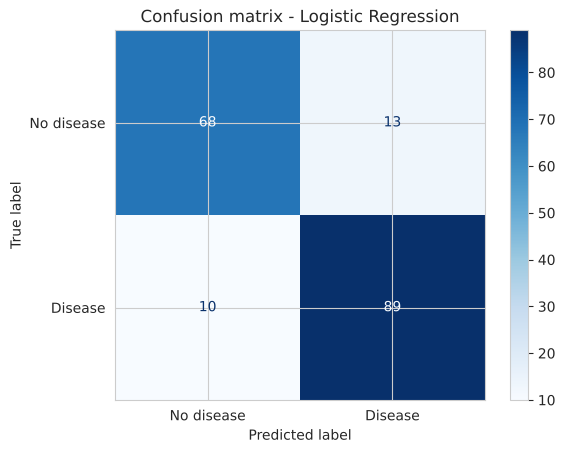

{'Model': 'Logistic Regression',
 'Accuracy': 0.8722222222222222,
 'Precision': 0.8725490196078431,
 'Recall': 0.898989898989899,
 'F1': 0.8855721393034826,
 'Train Time (s)': 0.054558753967285156}

In [19]:
res = evaluate_model(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                     X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression")
results_before.append(res); res

### 5.4 Decision Tree

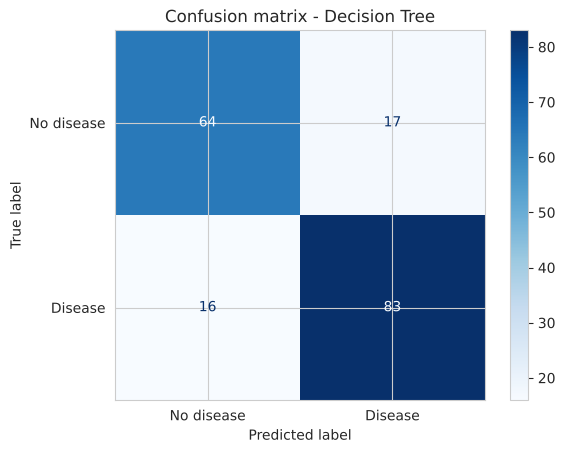

{'Model': 'Decision Tree',
 'Accuracy': 0.8166666666666667,
 'Precision': 0.83,
 'Recall': 0.8383838383838383,
 'F1': 0.8341708542713567,
 'Train Time (s)': 0.0037250518798828125}

In [20]:
res = evaluate_model(DecisionTreeClassifier(random_state=RANDOM_STATE),
                     X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree")
results_before.append(res); res

### 5.5 Random Forest

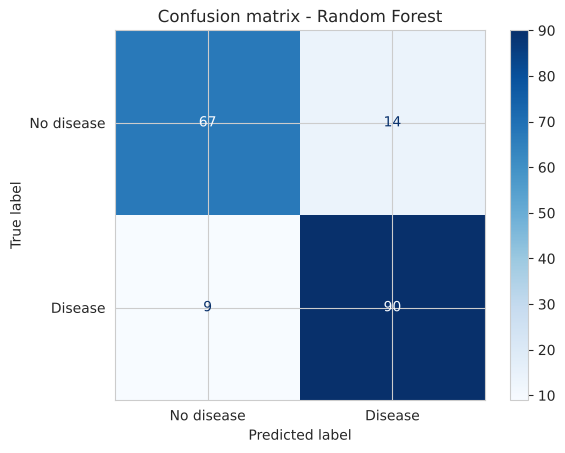

{'Model': 'Random Forest',
 'Accuracy': 0.8722222222222222,
 'Precision': 0.8653846153846154,
 'Recall': 0.9090909090909091,
 'F1': 0.8866995073891626,
 'Train Time (s)': 0.13321781158447266}

In [21]:
res = evaluate_model(RandomForestClassifier(random_state=RANDOM_STATE),
                     X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest")
results_before.append(res); res

### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1,Train Time (s)
Model,,,,,
KNN,0.8889,0.8835,0.9192,0.9010,0.0055
Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0546
Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0037
Random Forest,0.8722,0.8654,0.9091,0.8867,0.1332


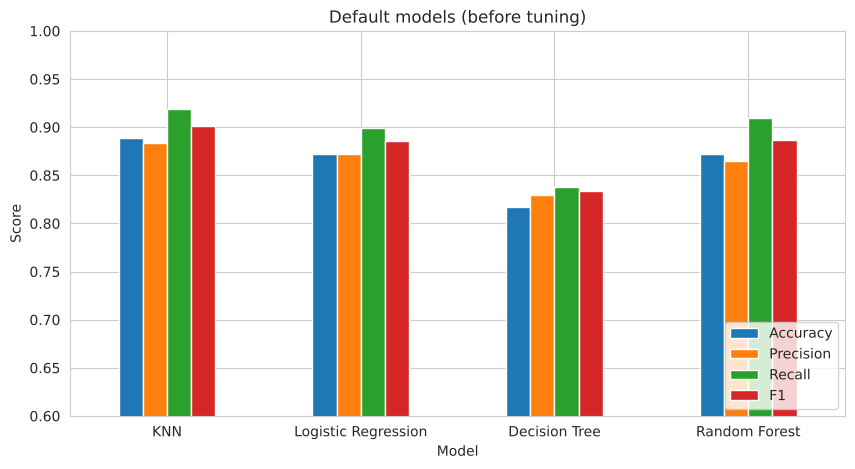

In [22]:
df_before = pd.DataFrame(results_before).set_index("Model")
display(df_before.round(4))
df_before[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Default models (before tuning)")
plt.ylabel("Score"); plt.ylim(0.6, 1); plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> **KNN achieved the highest default test accuracy (88.9%)**, followed by Logistic Regression and Random Forest (both 87.2%) and Decision Tree (81.7%). With only 180 test records, one patient equals about 0.56 percentage points, so the top three are close.
>
> In medical diagnosis **accuracy alone is not the most important metric; recall should be prioritised.** A false negative (a sick patient labelled healthy) can delay treatment with serious consequences, whereas a false positive usually only leads to further tests. A high-recall model catches more true patients, while precision/F1 keep the number of false alarms in check. Here KNN also has the best recall (91.9%).

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [3, 5, 7, 9, 11, 15], "weights": ["uniform", "distance"],
             "metric": ["euclidean", "manhattan"]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
            {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l1", "l2"], "solver": ["liblinear"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"max_depth": [3, 5, 7, 10, None], "min_samples_split": [2, 5, 10],
             "min_samples_leaf": [1, 2, 4], "criterion": ["gini", "entropy"]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
            {"n_estimators": [100, 200], "max_depth": [5, 10, None],
             "min_samples_split": [2, 5], "max_features": ["sqrt", "log2"]}),
}

def tune_and_evaluate(name, X_tr, X_te, show_cm=True):
    """Grid search with 5-fold CV, then refit best model and evaluate on the test set."""
    est, grid = param_grids[name]
    gs = GridSearchCV(est, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_tr, y_train)
    print(f"Best params : {gs.best_params_}")
    print(f"Mean CV acc : {gs.best_score_:.4f}")
    res = evaluate_model(gs.best_estimator_.__class__(**gs.best_params_,
                         **({"random_state": RANDOM_STATE} if "random_state" in est.get_params() else {}),
                         **({"max_iter": 2000} if name == "Logistic Regression" else {})),
                         X_tr, X_te, y_train, y_test, name, show_cm)
    res["Best CV Score"] = gs.best_score_
    res["Best Params"] = gs.best_params_
    return res

results_tuned = []

### 6.2 Tune KNN

Best params : {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Mean CV acc : 0.8803


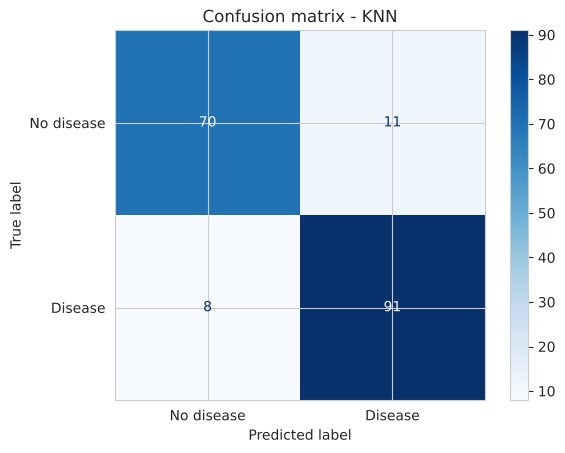

{'Model': 'KNN',
 'Accuracy': 0.8944444444444445,
 'Precision': 0.8921568627450981,
 'Recall': 0.9191919191919192,
 'F1': 0.9054726368159204,
 'Train Time (s)': 0.0012595653533935547,
 'Best CV Score': np.float64(0.8803418803418804),
 'Best Params': {'metric': 'manhattan',
  'n_neighbors': 11,
  'weights': 'distance'}}

In [24]:
results_tuned.append(tune_and_evaluate("KNN", X_train_scaled, X_test_scaled)); results_tuned[-1]

### 6.3 Tune Logistic Regression

Best params : {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Mean CV acc : 0.8651


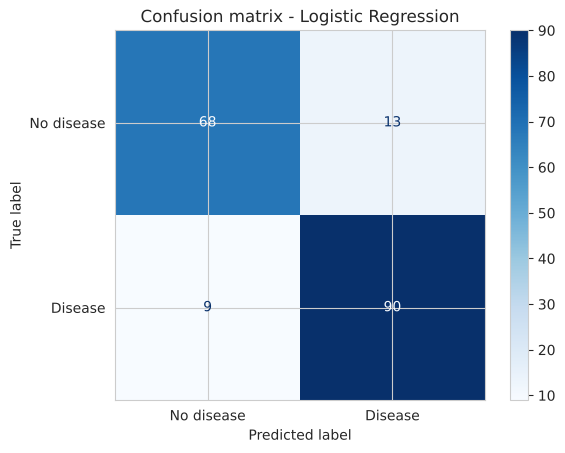

{'Model': 'Logistic Regression',
 'Accuracy': 0.8777777777777778,
 'Precision': 0.8737864077669902,
 'Recall': 0.9090909090909091,
 'F1': 0.8910891089108911,
 'Train Time (s)': 0.0017464160919189453,
 'Best CV Score': np.float64(0.86505439005439),
 'Best Params': {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}}

In [25]:
results_tuned.append(tune_and_evaluate("Logistic Regression", X_train_scaled, X_test_scaled)); results_tuned[-1]

### 6.4 Tune Decision Tree

Best params : {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mean CV acc : 0.8344


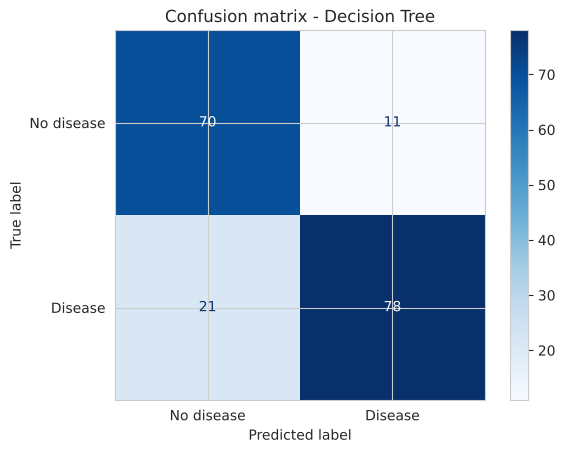

{'Model': 'Decision Tree',
 'Accuracy': 0.8222222222222222,
 'Precision': 0.8764044943820225,
 'Recall': 0.7878787878787878,
 'F1': 0.8297872340425532,
 'Train Time (s)': 0.0024869441986083984,
 'Best CV Score': np.float64(0.8344308469308469),
 'Best Params': {'criterion': 'entropy',
  'max_depth': 5,
  'min_samples_leaf': 1,
  'min_samples_split': 2}}

In [26]:
results_tuned.append(tune_and_evaluate("Decision Tree", X_train_scaled, X_test_scaled)); results_tuned[-1]

### 6.5 Tune Random Forest

Best params : {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Mean CV acc : 0.8748


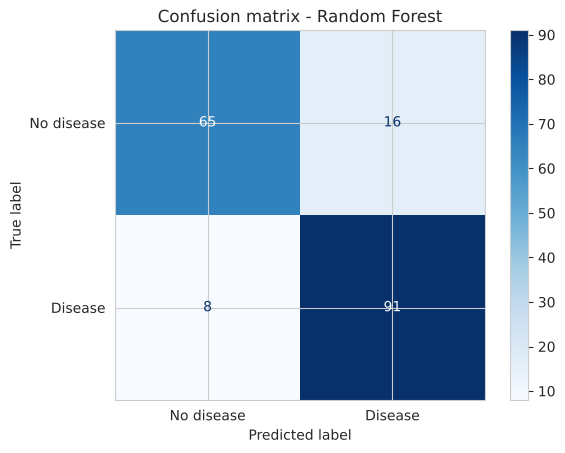

{'Model': 'Random Forest',
 'Accuracy': 0.8666666666666667,
 'Precision': 0.8504672897196262,
 'Recall': 0.9191919191919192,
 'F1': 0.883495145631068,
 'Train Time (s)': 0.17973971366882324,
 'Best CV Score': np.float64(0.8747766122766123),
 'Best Params': {'max_depth': None,
  'max_features': 'sqrt',
  'min_samples_split': 5,
  'n_estimators': 100}}

In [27]:
results_tuned.append(tune_and_evaluate("Random Forest", X_train_scaled, X_test_scaled)); results_tuned[-1]

### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

,Accuracy,Precision,Recall,F1,Train Time (s),Best CV Score
Model,,,,,,
KNN,0.8944,0.8922,0.9192,0.9055,0.0013,0.8803
Logistic Regression,0.8778,0.8738,0.9091,0.8911,0.0017,0.8651
Decision Tree,0.8222,0.8764,0.7879,0.8298,0.0025,0.8344
Random Forest,0.8667,0.8505,0.9192,0.8835,0.1797,0.8748


,Accuracy before,Accuracy tuned,F1 before,F1 tuned,Acc change
Model,,,,,
KNN,0.8889,0.8944,0.9010,0.9055,0.0056
Logistic Regression,0.8722,0.8778,0.8856,0.8911,0.0056
Decision Tree,0.8167,0.8222,0.8342,0.8298,0.0056
Random Forest,0.8722,0.8667,0.8867,0.8835,-0.0056


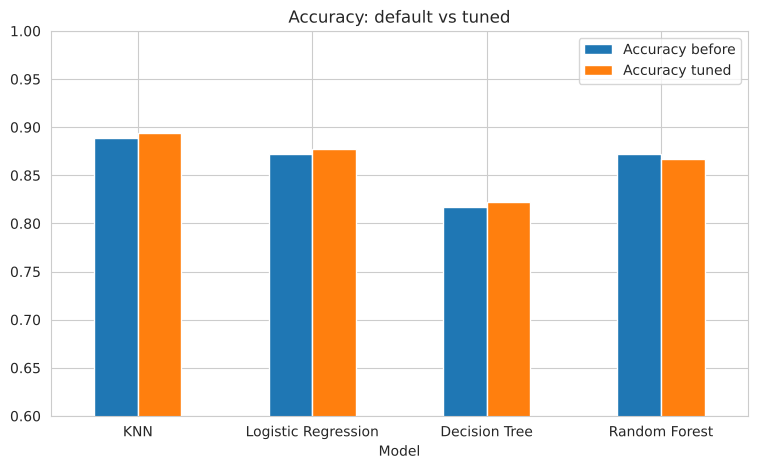

In [28]:
df_tuned = pd.DataFrame(results_tuned).set_index("Model")
display(df_tuned.drop(columns="Best Params").round(4))
comp = pd.DataFrame({"Accuracy before": df_before["Accuracy"], "Accuracy tuned": df_tuned["Accuracy"],
                     "F1 before": df_before["F1"], "F1 tuned": df_tuned["F1"]})
comp["Acc change"] = comp["Accuracy tuned"] - comp["Accuracy before"]
display(comp.round(4))
comp[["Accuracy before", "Accuracy tuned"]].plot(kind="bar", figsize=(9, 5))
plt.title("Accuracy: default vs tuned"); plt.ylim(0.6, 1); plt.xticks(rotation=0); plt.show()

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> **Not every model improved.** Test accuracy rose by ~0.6 points (one extra correct patient) for KNN (88.9→89.4%), Logistic Regression (87.2→87.8%) and Decision Tree (81.7→82.2%), but **fell slightly for Random Forest** (87.2→86.7%). F1 also dropped slightly for Decision Tree and Random Forest.
>
> The Decision Tree gained the most conceptually: the default tree grows until it is pure and overfits, while tuning limited it to `max_depth=5` (precision up from 0.83 to 0.88, though recall dropped from 0.84 to 0.79). KNN gained the most in F1 (+0.0045) from choosing a better k (11), distance weighting and Manhattan distance. Random Forest and Logistic Regression are already well regularised by default, so there was little to gain. Overall the changes are within noise on a 180-sample test set; the cross-validated scores (best CV accuracy 0.83-0.88) are the more reliable evidence.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

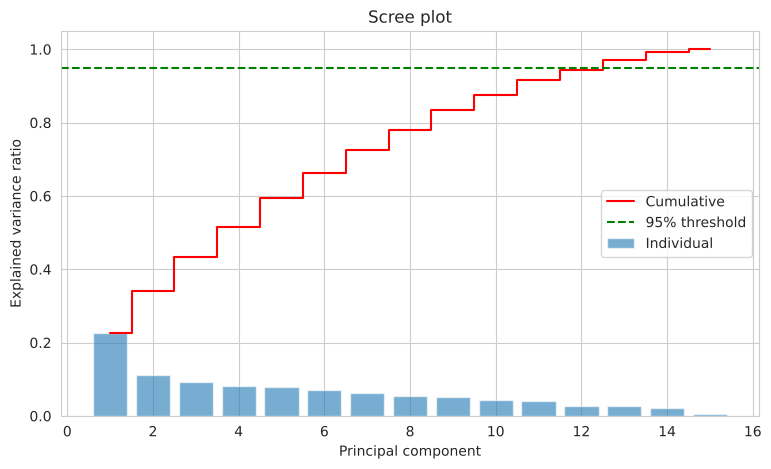

In [29]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)   # fit on training data only
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
plt.figure(figsize=(9, 5))
plt.bar(range(1, len(evr) + 1), evr, alpha=0.6, label="Individual")
plt.step(range(1, len(evr) + 1), cum, where="mid", color="red", label="Cumulative")
plt.axhline(0.95, color="green", ls="--", label="95% threshold")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio")
plt.title("Scree plot"); plt.legend(); plt.show()

### 7.2 Determine the number of components for 95% variance

In [30]:
n_95 = int(np.argmax(cum >= 0.95) + 1)
print("Components needed for 95% variance:", n_95)
print("Original number of features       :", X_train_scaled.shape[1])

Components needed for 95% variance: 13
Original number of features       : 15


### 7.3 Transform the training and testing sets

In [31]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("X_train_pca:", X_train_pca.shape, "| X_test_pca:", X_test_pca.shape)
print("Variance retained:", pca.explained_variance_ratio_.sum().round(4))
print("Feature reduction: %.1f%%" % (100 * (1 - pca.n_components_ / X_train_scaled.shape[1])))

X_train_pca: (719, 13) | X_test_pca: (180, 13)
Variance retained: 0.972
Feature reduction: 13.3%


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

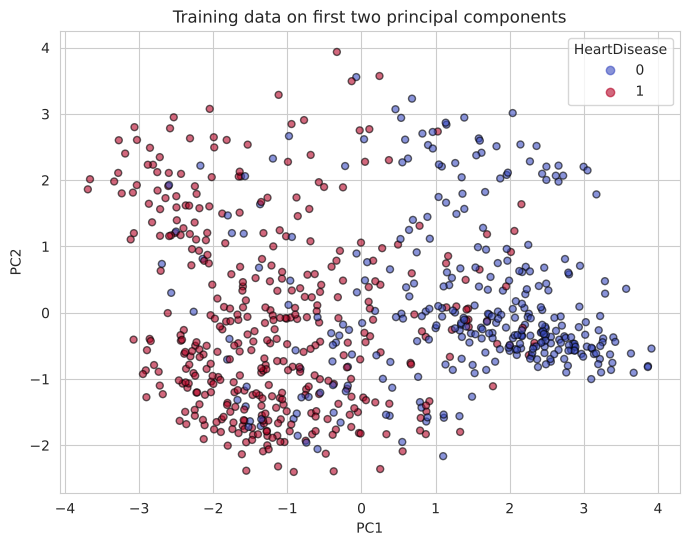

In [32]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="coolwarm", alpha=0.6, edgecolor="k", s=25)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Training data on first two principal components")
plt.legend(*sc.legend_elements(), title="HeartDisease")
plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> **13 principal components** are needed to retain at least 95% of the variance (they actually retain **97.2%**; 12 would fall below 95%). The number of features is reduced from 15 to 13, a reduction of **about 13.3%**. The scree plot shows variance is spread fairly evenly over many components, so there is little redundancy to compress.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

Best params : {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Mean CV acc : 0.8762


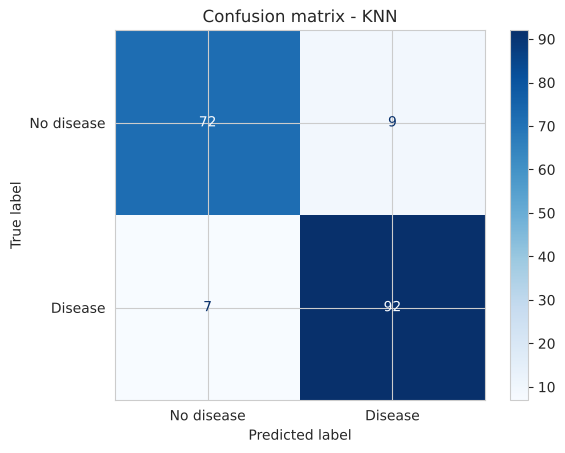

{'Model': 'KNN',
 'Accuracy': 0.9111111111111111,
 'Precision': 0.9108910891089109,
 'Recall': 0.9292929292929293,
 'F1': 0.92,
 'Train Time (s)': 0.0011990070343017578,
 'Best CV Score': np.float64(0.8761557886557888),
 'Best Params': {'metric': 'manhattan',
  'n_neighbors': 15,
  'weights': 'distance'}}

In [33]:
results_pca = []
results_pca.append(tune_and_evaluate("KNN", X_train_pca, X_test_pca)); results_pca[-1]

### 8.2 Logistic Regression after PCA

Best params : {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Mean CV acc : 0.8678


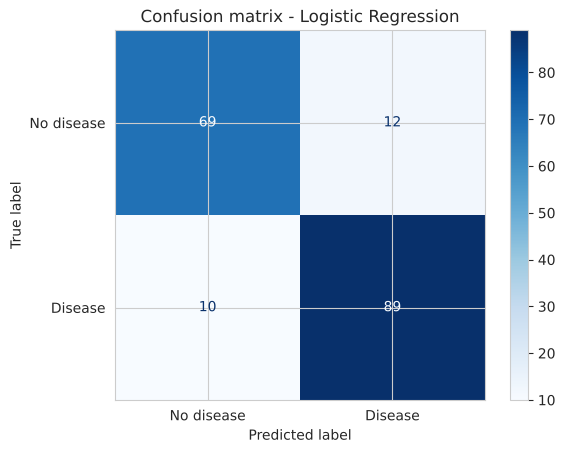

{'Model': 'Logistic Regression',
 'Accuracy': 0.8777777777777778,
 'Precision': 0.8811881188118812,
 'Recall': 0.898989898989899,
 'F1': 0.89,
 'Train Time (s)': 0.0017082691192626953,
 'Best CV Score': np.float64(0.8678321678321679),
 'Best Params': {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}}

In [34]:
results_pca.append(tune_and_evaluate("Logistic Regression", X_train_pca, X_test_pca)); results_pca[-1]

### 8.3 Decision Tree after PCA

Best params : {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mean CV acc : 0.8345


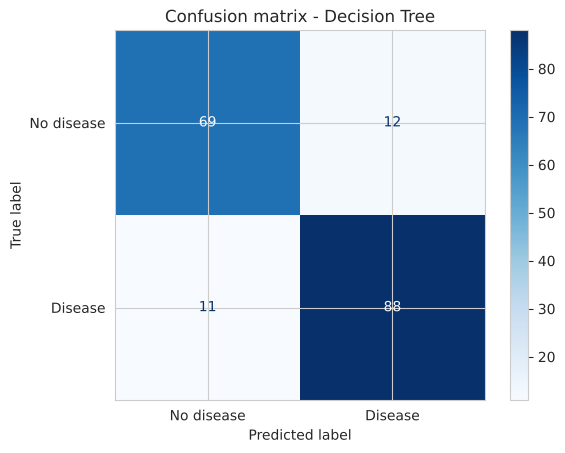

{'Model': 'Decision Tree',
 'Accuracy': 0.8722222222222222,
 'Precision': 0.88,
 'Recall': 0.8888888888888888,
 'F1': 0.8844221105527639,
 'Train Time (s)': 0.003813505172729492,
 'Best CV Score': np.float64(0.8344599844599845),
 'Best Params': {'criterion': 'entropy',
  'max_depth': 3,
  'min_samples_leaf': 1,
  'min_samples_split': 2}}

In [35]:
results_pca.append(tune_and_evaluate("Decision Tree", X_train_pca, X_test_pca)); results_pca[-1]

### 8.4 Random Forest after PCA

Best params : {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Mean CV acc : 0.8692


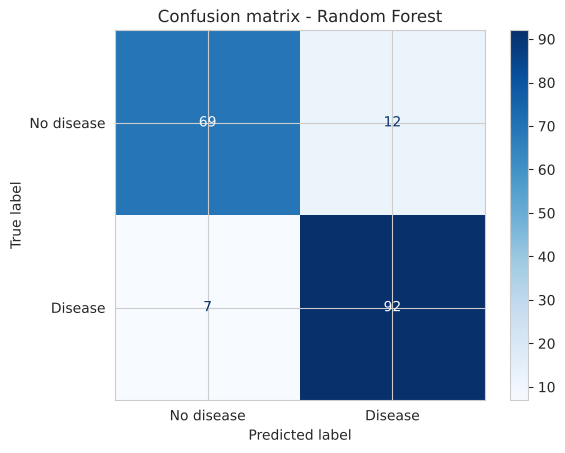

{'Model': 'Random Forest',
 'Accuracy': 0.8944444444444445,
 'Precision': 0.8846153846153846,
 'Recall': 0.9292929292929293,
 'F1': 0.9064039408866995,
 'Train Time (s)': 0.150010347366333,
 'Best CV Score': np.float64(0.8692307692307691),
 'Best Params': {'max_depth': 5,
  'max_features': 'sqrt',
  'min_samples_split': 2,
  'n_estimators': 100}}

In [36]:
results_pca.append(tune_and_evaluate("Random Forest", X_train_pca, X_test_pca)); results_pca[-1]

### 8.5 Comparison table of all four models after PCA

In [37]:
df_pca = pd.DataFrame(results_pca).set_index("Model")
display(df_pca.drop(columns="Best Params").round(4))

,Accuracy,Precision,Recall,F1,Train Time (s),Best CV Score
Model,,,,,,
KNN,0.9111,0.9109,0.9293,0.9200,0.0012,0.8762
Logistic Regression,0.8778,0.8812,0.8990,0.8900,0.0017,0.8678
Decision Tree,0.8722,0.8800,0.8889,0.8844,0.0038,0.8345
Random Forest,0.8944,0.8846,0.9293,0.9064,0.1500,0.8692


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> After PCA, **KNN performed best** (accuracy 91.1%, precision 91.1%, recall 92.9%, F1 0.920), followed by Random Forest (89.4%), Logistic Regression (87.8%) and Decision Tree (87.2%). **Yes, it is the same model** as the best tuned model before PCA, which was also KNN (89.4% accuracy, F1 0.906).

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
final = pd.DataFrame({
    "Accuracy (Before PCA)": df_tuned["Accuracy"],
    "Accuracy (After PCA)": df_pca["Accuracy"],
    "F1 (Before PCA)": df_tuned["F1"],
    "F1 (After PCA)": df_pca["F1"],
    "Training Time Before (s)": df_tuned["Train Time (s)"],
    "Training Time After (s)": df_pca["Train Time (s)"],
})
final["No. of Features"] = f"{X_train_scaled.shape[1]} -> {X_train_pca.shape[1]}"
final.round(4)

,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
Model,,,,,,,
KNN,0.8944,0.9111,0.9055,0.9200,0.0013,0.0012,15 -> 13
Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.0017,0.0017,15 -> 13
Decision Tree,0.8222,0.8722,0.8298,0.8844,0.0025,0.0038,15 -> 13
Random Forest,0.8667,0.8944,0.8835,0.9064,0.1797,0.1500,15 -> 13


### 9.2 Visualise the before vs after PCA comparison

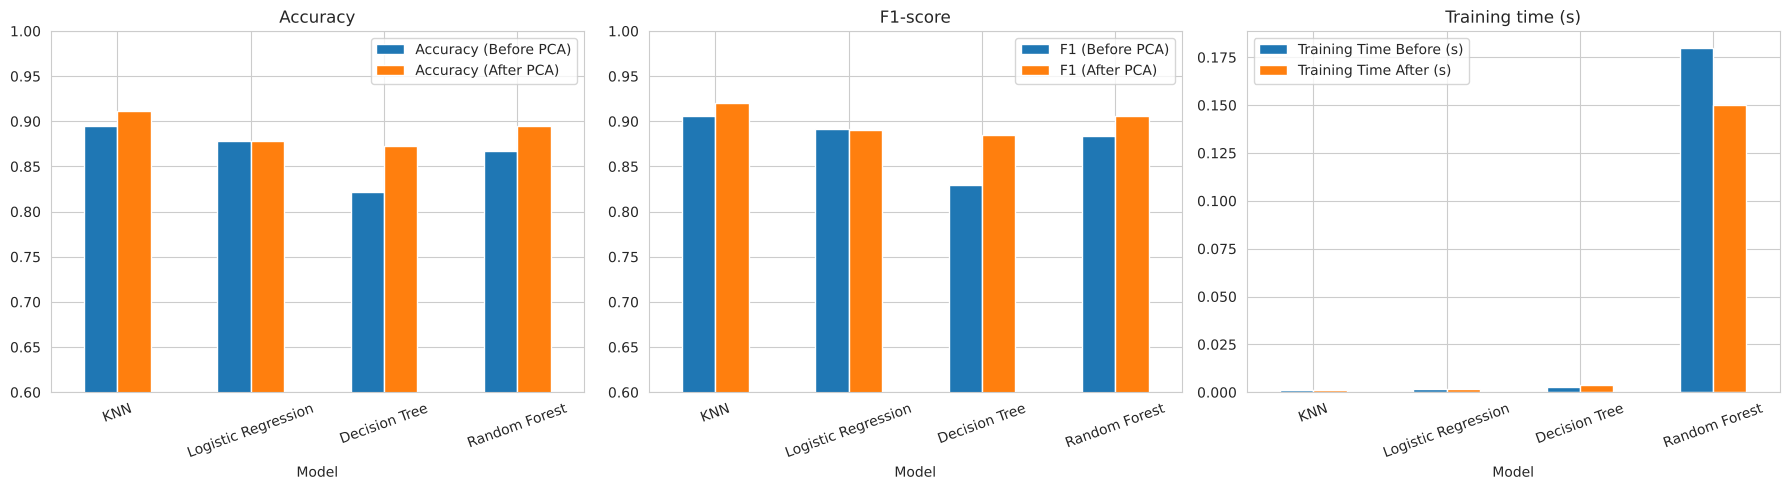

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
final[["Accuracy (Before PCA)", "Accuracy (After PCA)"]].plot(kind="bar", ax=axes[0], ylim=(0.6, 1))
axes[0].set_title("Accuracy"); axes[0].tick_params(axis="x", rotation=20)
final[["F1 (Before PCA)", "F1 (After PCA)"]].plot(kind="bar", ax=axes[1], ylim=(0.6, 1))
axes[1].set_title("F1-score"); axes[1].tick_params(axis="x", rotation=20)
final[["Training Time Before (s)", "Training Time After (s)"]].plot(kind="bar", ax=axes[2])
axes[2].set_title("Training time (s)"); axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Comparing tuned models before vs after PCA on the test set: **KNN improved** (89.4→91.1% accuracy, F1 0.906→0.920), **Random Forest improved** (86.7→89.4%, F1 0.884→0.906) and **Decision Tree improved the most** (82.2→87.2%, F1 0.830→0.884). **Logistic Regression stayed the same** in accuracy (87.8%) with an almost identical F1 (0.891→0.890). No model declined in accuracy.
>
> Caveat: the 5-fold CV scores on the training data did *not* show the same gains (KNN 0.880→0.876, RF 0.875→0.869, DT 0.834→0.835, LR 0.865→0.868), so the test-set improvements are probably partly due to the particular 180-record split rather than a real benefit of PCA.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> PCA reduced the feature count from 15 to 13 (about 13% fewer). Training times were already tiny, so the effect is negligible: Random Forest went from ~0.180 s to ~0.150 s, while KNN and Logistic Regression were unchanged (~0.001-0.002 s) and Decision Tree was slightly slower (0.0025→0.0038 s), which is just timing noise. PCA itself also costs time to fit. With only 899 records and 15 features, there is almost no computational benefit; savings would matter with many features or very large datasets.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> On this dataset PCA **did not hurt, and on the test set slightly improved**, accuracy for three models and left Logistic Regression unchanged. Possible reasons: (1) the dataset is small and has few features, and 13 components keep 97% of the variance, so almost no information is lost; (2) KNN benefits because PCA rotates and decorrelates the (one-hot, correlated) features and reduces noisy dimensions, making distances more meaningful; (3) the Decision Tree and Random Forest benefit because PCA components are uncorrelated and the shallow trees overfit less; (4) Logistic Regression is linear, so a rotation of the features changes little. Because CV scores did not improve, I regard the effect as roughly neutral. The cost is **interpretability**: each component mixes all original features, so it is harder to explain which clinical factor drives a prediction.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> Reducing dimensionality lowers computational cost, memory use and overfitting risk, and removes multicollinearity, but it can discard discriminative information, because PCA keeps variance and not class separation, and it reduces interpretability. Keeping more components preserves accuracy but saves less computation; keeping fewer saves more but risks accuracy loss. Here the trade-off was almost free, but also gave little benefit.
>
> PCA is preferable when there are **many features** (e.g. genomics, images, text, sensor data), when features are highly correlated, when training/inference must be fast or memory-limited, when data must be visualised in 2D/3D, or to denoise data. For a small clinical dataset where explaining the model to doctors matters, the original features are generally the better choice.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.